In [5]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)
    for filename in filenames[:5]:
        print("  ", filename)

/kaggle/input
/kaggle/input/competitions
/kaggle/input/competitions/aptos2019-blindness-detection
   sample_submission.csv
   train.csv
   test.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train_images
   ef476be214d4.png
   6dcde47060f9.png
   ec363f48867b.png
   17f6c7072f61.png
   b49b2fac2514.png
/kaggle/input/competitions/aptos2019-blindness-detection/test_images
   755615db51d3.png
   d8f6c660bf2d.png
   619ce2c77917.png
   94a6e4f3c625.png
   ee506d853270.png


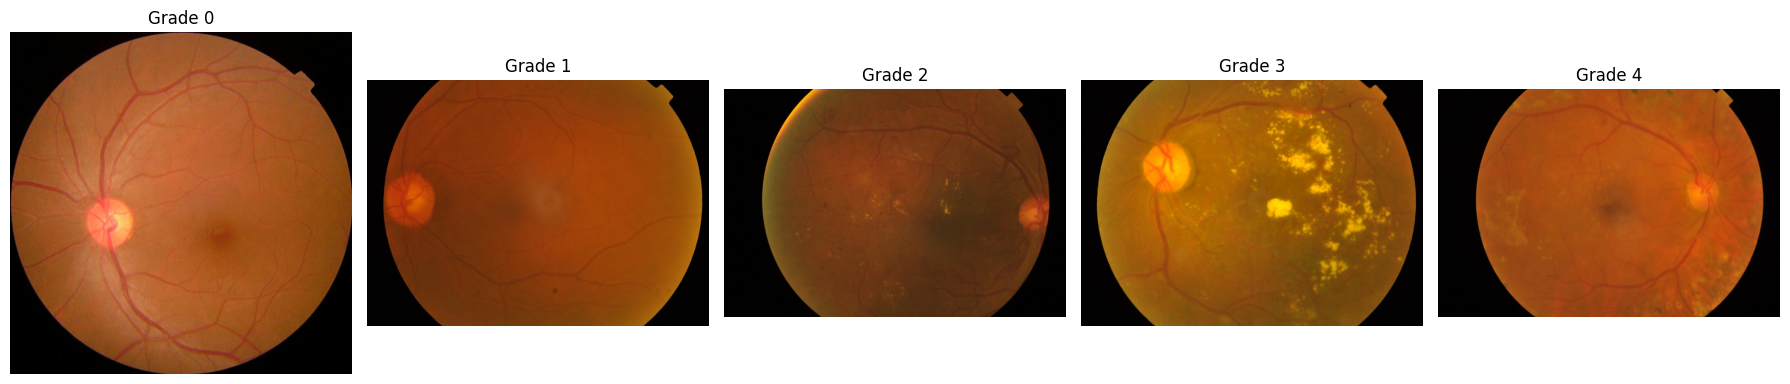

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_folder = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"

# Display one image from each grade
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for grade in range(5):

    # Get an image belonging to this grade
    image_id = train_df[train_df["diagnosis"] == grade]["id_code"].iloc[0]

    image_path = os.path.join(image_folder, image_id + ".png")

    img = Image.open(image_path)

    axes[grade].imshow(img)
    axes[grade].set_title(f"Grade {grade}")
    axes[grade].axis("off")

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

# Load the training CSV
train_path = "/kaggle/input/competitions/aptos2019-blindness-detection/train.csv"

train_df = pd.read_csv(train_path)

# Display dataset information
print("Dataset Shape:", train_df.shape)

print("\nFirst 5 Rows:")
display(train_df.head())

print("\nColumn Names:")
print(train_df.columns)

print("\nGrade Distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

Dataset Shape: (3662, 2)

First 5 Rows:


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0



Column Names:
Index(['id_code', 'diagnosis'], dtype='object')

Grade Distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


In [8]:
from PIL import Image
import os
from collections import Counter

image_folder = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"

image_sizes = Counter()
image_modes = Counter()
corrupted_images = []

for filename in os.listdir(image_folder):

    image_path = os.path.join(image_folder, filename)

    try:
        with Image.open(image_path) as img:
            image_sizes[img.size] += 1
            image_modes[img.mode] += 1

    except Exception:
        corrupted_images.append(filename)

print("Total images:", len(os.listdir(image_folder)))

print("\nImage dimensions and counts:")
for size, count in image_sizes.items():
    print(size, ":", count)

print("\nImage color modes:")
print(image_modes)

print("\nCorrupted images:", len(corrupted_images))

Total images: 3662

Image dimensions and counts:
(819, 614) : 287
(3216, 2136) : 410
(2588, 1958) : 533
(1050, 1050) : 974
(3388, 2588) : 141
(2048, 1536) : 351
(2416, 1736) : 638
(1504, 1000) : 92
(1476, 1117) : 14
(2144, 1424) : 28
(4288, 2848) : 52
(640, 480) : 42
(1844, 1226) : 61
(2896, 1944) : 34
(1467, 1110) : 2
(474, 358) : 2
(2146, 1764) : 1

Image color modes:
Counter({'RGB': 3662})

Corrupted images: 0


In [9]:
import pandas as pd

train_path = "/kaggle/input/competitions/aptos2019-blindness-detection/train.csv"

train_df = pd.read_csv(train_path)

print(train_df.head())
print("Total samples:", len(train_df))

        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0
Total samples: 3662


In [10]:
from sklearn.model_selection import train_test_split

# Step 1: Separate 70% training data and 30% temporary data
train_data, temp_data = train_test_split(
    train_df,
    test_size=0.30,
    stratify=train_df["diagnosis"],
    random_state=42
)

# Step 2: Divide the remaining 30% equally
val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=temp_data["diagnosis"],
    random_state=42
)

# Step 3: Display the number of samples
print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_data))

# Step 4: Check grade distribution in each split
for name, data in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Testing", test_data)
]:
    print(f"\n{name} grade distribution:")
    print(data["diagnosis"].value_counts().sort_index())

Training samples: 2563
Validation samples: 549
Testing samples: 550

Training grade distribution:
diagnosis
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64

Validation grade distribution:
diagnosis
0    271
1     55
2    150
3     29
4     44
Name: count, dtype: int64

Testing grade distribution:
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


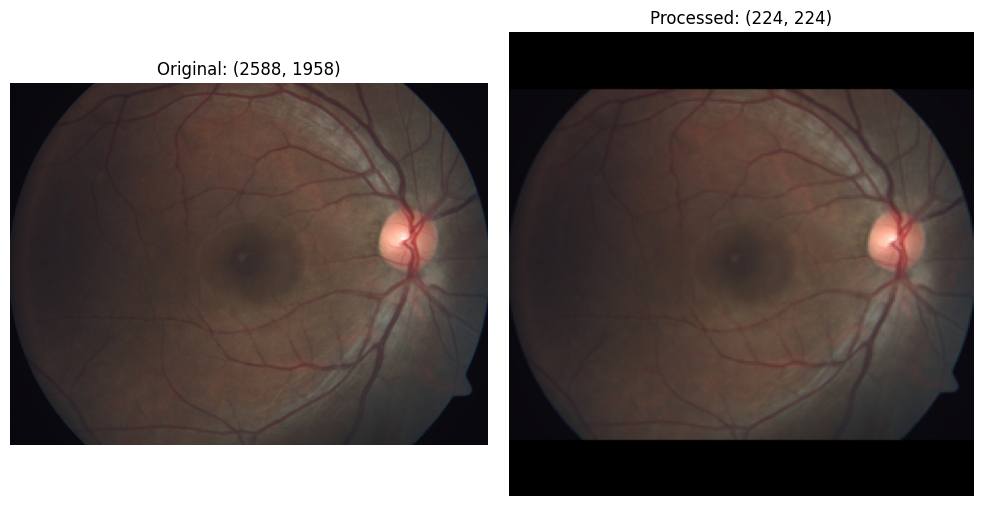

In [11]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import os

# Select one training image
image_id = train_data.iloc[0]["id_code"]

image_path = os.path.join(
    image_folder,
    image_id + ".png"
)

# Open the original image
original_image = Image.open(image_path).convert("RGB")

# Resize proportionally and add black padding
processed_image = ImageOps.pad(
    original_image,
    (224, 224),
    method=Image.Resampling.LANCZOS,
    color=(0, 0, 0)
)

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title(f"Original: {original_image.size}")
axes[0].axis("off")

axes[1].imshow(processed_image)
axes[1].set_title(f"Processed: {processed_image.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

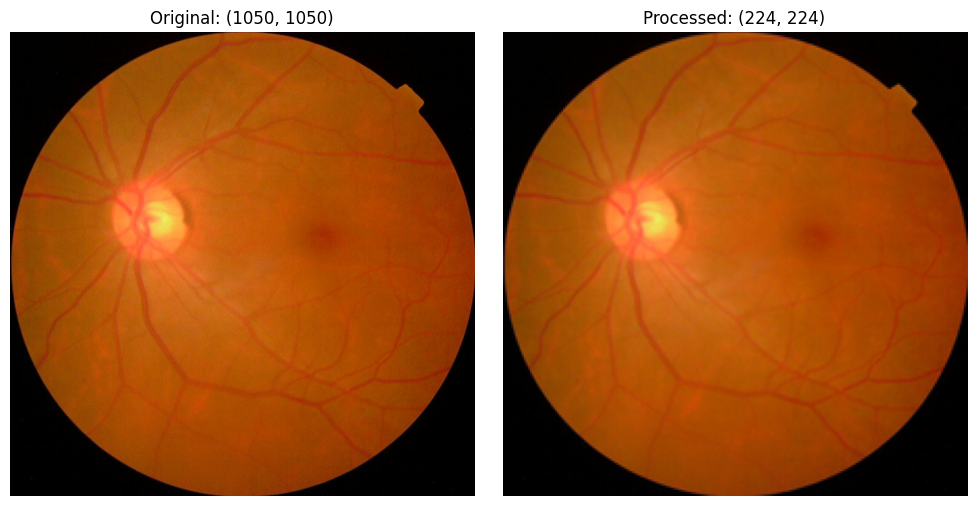

In [12]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import os

# Select one training image
image_id = train_data.iloc[10]["id_code"]

image_path = os.path.join(
    image_folder,
    image_id + ".png"
)

# Open the original image
original_image = Image.open(image_path).convert("RGB")

# Resize proportionally and add black padding
processed_image = ImageOps.pad(
    original_image,
    (224, 224),
    method=Image.Resampling.LANCZOS,
    color=(0, 0, 0)
)

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title(f"Original: {original_image.size}")
axes[0].axis("off")

axes[1].imshow(processed_image)
axes[1].set_title(f"Processed: {processed_image.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

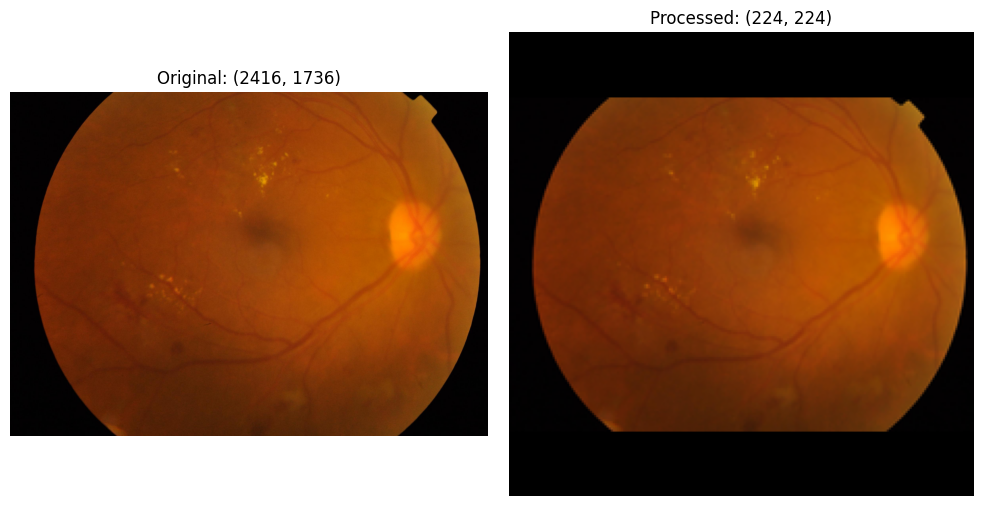

In [13]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import os

# Select one training image
image_id = train_data.iloc[100]["id_code"]

image_path = os.path.join(
    image_folder,
    image_id + ".png"
)

# Open the original image
original_image = Image.open(image_path).convert("RGB")

# Resize proportionally and add black padding
processed_image = ImageOps.pad(
    original_image,
    (224, 224),
    method=Image.Resampling.LANCZOS,
    color=(0, 0, 0)
)

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title(f"Original: {original_image.size}")
axes[0].axis("off")

axes[1].imshow(processed_image)
axes[1].set_title(f"Processed: {processed_image.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [32]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("TensorFlow is working!")

TensorFlow version: 2.21.0
Available GPUs: []
TensorFlow is working!


In [15]:
import numpy as np
from tensorflow.keras.applications.resnet50 import preprocess_input

# Convert the resized PIL image into a NumPy array
image_array = np.array(processed_image).astype(np.float32)

# Apply ResNet50 ImageNet preprocessing
normalized_image = preprocess_input(image_array.copy())

# Display the results
print("Original array shape:", image_array.shape)
print("Normalized array shape:", normalized_image.shape)

print("Original pixel range:",
      image_array.min(), "to", image_array.max())

print("Normalized pixel range:",
      normalized_image.min(), "to", normalized_image.max())

Original array shape: (224, 224, 3)
Normalized array shape: (224, 224, 3)
Original pixel range: 0.0 to 255.0
Normalized pixel range: -123.68 to 131.32


In [16]:
import tensorflow as tf

BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)

print("TensorFlow version:", tf.__version__)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)

TensorFlow version: 2.21.0
Batch size: 32
Image size: (224, 224)


In [17]:
import tensorflow as tf
import numpy as np
from PIL import Image, ImageOps
from tensorflow.keras.applications.resnet50 import preprocess_input

def load_and_preprocess_image(image_id, label):

    # Convert byte string into a normal Python string
    if isinstance(image_id, (bytes, np.bytes_)):
        image_id = image_id.decode("utf-8")

    # Construct image path
    image_path = os.path.join(image_folder, image_id + ".png")

    # Load image and convert to RGB
    image = Image.open(image_path).convert("RGB")

    # Resize proportionally and add padding
    image = ImageOps.pad(
        image,
        IMAGE_SIZE,
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

    # Convert to NumPy array
    image = np.array(image).astype(np.float32)

    # Apply ResNet50 preprocessing
    image = preprocess_input(image)

    return image, np.int64(label)

In [18]:
# Select one image from the training dataset
sample_image_id = train_data.iloc[0]["id_code"]
sample_label = train_data.iloc[0]["diagnosis"]

# Apply our preprocessing function
sample_image, sample_label = load_and_preprocess_image(
    sample_image_id,
    sample_label
)

# Verify the output
print("Image ID:", sample_image_id)
print("Image shape:", sample_image.shape)
print("Diagnosis label:", sample_label)
print("Pixel value range:", sample_image.min(), "to", sample_image.max())

Image ID: 38f1901f214a
Image shape: (224, 224, 3)
Diagnosis label: 0
Pixel value range: -123.68 to 131.32


In [19]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [20]:
print("train_data:", "train_data" in globals())
print("val_data:", "val_data" in globals())
print("test_data:", "test_data" in globals())

train_data: True
val_data: True
test_data: True


In [21]:
train_image_ids = train_data["id_code"].values
train_labels = train_data["diagnosis"].values

train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_image_ids, train_labels)
)

In [22]:
import pandas as pd

train_path = "/kaggle/input/competitions/aptos2019-blindness-detection/train.csv"
train_df = pd.read_csv(train_path)

print(train_df.shape)

(3662, 2)


In [23]:
import os
import numpy as np
from PIL import Image, ImageOps

from tensorflow.keras.applications.resnet50 import preprocess_input

# Folder containing training retinal images
image_folder = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"

# Image dimensions
IMAGE_SIZE = (224, 224)

# Number of images processed in one batch
BATCH_SIZE = 32

print("Image folder exists:", os.path.exists(image_folder))
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Image folder exists: True
Image size: (224, 224)
Batch size: 32


In [24]:
def load_and_preprocess_image(image_id, label):

    # Step 1: Convert byte string into normal string
    if isinstance(image_id, (bytes, np.bytes_)):
        image_id = image_id.decode("utf-8")

    # Step 2: Construct the image path
    image_path = os.path.join(image_folder, image_id + ".png")

    # Step 3: Load image and convert to RGB
    image = Image.open(image_path).convert("RGB")

    # Step 4: Resize proportionally and add padding
    image = ImageOps.pad(
        image,
        IMAGE_SIZE,
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

    # Step 5: Convert image into NumPy array
    image = np.array(image).astype(np.float32)

    # Step 6: Apply ResNet50 preprocessing
    image = preprocess_input(image)

    # Step 7: Return processed image and label
    return image, np.int64(label)

In [25]:
# Select one image from the training dataset
sample_image_id = train_data.iloc[0]["id_code"]
sample_label = train_data.iloc[0]["diagnosis"]

# Process the selected image
processed_image, processed_label = load_and_preprocess_image(
    sample_image_id,
    sample_label
)

# Display the results
print("Image ID:", sample_image_id)
print("Processed image shape:", processed_image.shape)
print("Diagnosis label:", processed_label)
print(
    "Pixel value range:",
    processed_image.min(),
    "to",
    processed_image.max()
)

Image ID: 38f1901f214a
Processed image shape: (224, 224, 3)
Diagnosis label: 0
Pixel value range: -123.68 to 131.32


In [26]:
# Step 1: Extract image IDs and their labels
train_image_ids = train_data["id_code"].values
train_labels = train_data["diagnosis"].values

# Step 2: Create a TensorFlow dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_image_ids, train_labels)
)

# Step 3: Check the dataset
print("Number of training samples:", len(train_image_ids))
print("Dataset created successfully!")

Number of training samples: 2563
Dataset created successfully!


In [27]:
def process_image(image_id, label):

    image, label = tf.numpy_function(
        load_and_preprocess_image,
        [image_id, label],
        [tf.float32, tf.int64]
    )

    # Restore the image and label shapes
    image.set_shape((224, 224, 3))
    label.set_shape(())

    return image, label


train_dataset = train_dataset.map(
    process_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Image preprocessing connected to TensorFlow!")

Image preprocessing connected to TensorFlow!


In [28]:
# Get one image and its label from the dataset
for image, label in train_dataset.take(1):

    print("Image shape:", image.shape)
    print("Image data type:", image.dtype)
    print("Diagnosis label:", label.numpy())
    print("Pixel value range:", image.numpy().min(), "to", image.numpy().max())

Image shape: (224, 224, 3)
Image data type: <dtype: 'float32'>
Diagnosis label: 0
Pixel value range: -123.68 to 131.32


In [29]:
# Get validation image IDs and labels
val_image_ids = val_data["id_code"].values
val_labels = val_data["diagnosis"].values

# Create validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_image_ids, val_labels)
)

# Apply image preprocessing
val_dataset = val_dataset.map(
    process_image,
    num_parallel_calls=tf.data.AUTOTUNE
)


# Get test image IDs and labels
test_image_ids = test_data["id_code"].values
test_labels = test_data["diagnosis"].values

# Create test dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_image_ids, test_labels)
)

# Apply image preprocessing
test_dataset = test_dataset.map(
    process_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Validation and test datasets created successfully!")
print("Validation samples:", len(val_image_ids))
print("Test samples:", len(test_image_ids))

Validation and test datasets created successfully!
Validation samples: 549
Test samples: 550


In [30]:
# Prepare training dataset
train_dataset = train_dataset.shuffle(
    buffer_size=len(train_data),
    seed=42
)

train_dataset = train_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)


# Prepare validation dataset
val_dataset = val_dataset.batch(BATCH_SIZE)

val_dataset = val_dataset.prefetch(
    tf.data.AUTOTUNE
)


# Prepare test dataset
test_dataset = test_dataset.batch(BATCH_SIZE)

test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)

print("All three datasets are ready for model training!")

All three datasets are ready for model training!


In [33]:
# Get one batch from the training dataset
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Minimum pixel value: -123.68
Maximum pixel value: 151.061


In [34]:
# Load pretrained ResNet50
base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

print("ResNet50 loaded successfully!")
print("Total layers:", len(base_model.layers))


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
ResNet50 loaded successfully!
Total layers: 175
